# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Налаштування формату виведення чисел
pd.options.display.float_format = '{:,.2f}'.format

# Завантаження датасету
df = pd.read_csv('CarPrice_Assignment.csv')

# Визначення кількості об'єктів і ознак
print(f"Кількість об'єктів (рядків): {df.shape[0]}")
print(f"Кількість ознак (стовпців): {df.shape[1]}")

# Назви стовпців та типи даних
print("\nТипи даних та назви стовпців:")
print(df.dtypes)

# Визначення цільової змінної
target_col = 'price'
print(f"\nЦільова змінна: {target_col}")

# Основні статистичні характеристики числових ознак
print("\nОсновні статистичні характеристики числових даних:")
display(df.describe())

display(df.head())

Кількість об'єктів (рядків): 205
Кількість ознак (стовпців): 26

Типи даних та назви стовпців:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm               int64
citympg               int64
highwaympg            int64
price               float64
dtype: object

Цільова змінна: price

Основні статистичні характеристики числових даних:


,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.00,205.00,205.00,205.00,205.00,205.00,205.00,205.00,205.00,205.00,205.00,205.00,205.00,205.00,205.00,205.00
mean,103.00,0.83,98.76,174.05,65.91,53.72,"2,555.57",126.91,3.33,3.26,10.14,104.12,"5,125.12",25.22,30.75,"13,276.71"
std,59.32,1.25,6.02,12.34,2.15,2.44,520.68,41.64,0.27,0.31,3.97,39.54,476.99,6.54,6.89,"7,988.85"
min,1.00,-2.00,86.60,141.10,60.30,47.80,"1,488.00",61.00,2.54,2.07,7.00,48.00,"4,150.00",13.00,16.00,"5,118.00"
25%,52.00,0.00,94.50,166.30,64.10,52.00,"2,145.00",97.00,3.15,3.11,8.60,70.00,"4,800.00",19.00,25.00,"7,788.00"
50%,103.00,1.00,97.00,173.20,65.50,54.10,"2,414.00",120.00,3.31,3.29,9.00,95.00,"5,200.00",24.00,30.00,"10,295.00"
75%,154.00,2.00,102.40,183.10,66.90,55.50,"2,935.00",141.00,3.58,3.41,9.40,116.00,"5,500.00",30.00,34.00,"16,503.00"
max,205.00,3.00,120.90,208.10,72.30,59.80,"4,066.00",326.00,3.94,4.17,23.00,288.00,"6,600.00",49.00,54.00,"45,400.00"


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,"13,495.00"
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,"16,500.00"
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.50,...,152,mpfi,2.68,3.47,9.00,154,5000,19,26,"16,500.00"
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.80,...,109,mpfi,3.19,3.40,10.00,102,5500,24,30,"13,950.00"
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.40,...,136,mpfi,3.19,3.40,8.00,115,5500,18,22,"17,450.00"


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [16]:
# Перевірка на пропущені значення
print("Кількість пропущених значень (NaN) у стовпцях:")
print(df.isnull().sum())

# Перевірка на повні дублікати (без урахування car_ID)
df_no_id = df.drop(columns=['car_ID'])
duplicates_count = df_no_id.duplicated().sum()
print(f"\nКількість повних дублікатів (за змістовими характеристиками): {duplicates_count}")

# Кількість унікальних значень в ознаках
print("\nКількість унікальних значень у кожній ознаці:")
print(df.nunique())

Кількість пропущених значень (NaN) у стовпцях:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Кількість повних дублікатів (за змістовими характеристиками): 0

Кількість унікальних значень у кожній ознаці:
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength       

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [17]:
# Зберігаємо car_ID окремо для ідентифікації автомобілів у майбутньому
if 'car_ID' in df.columns:
    car_ids = df['car_ID'].copy()
    # Видаляємо car_ID зі списку ознак для навчання моделей
    df = df.drop(columns=['car_ID'])
    print("Ознаку car_ID успішно відокремлено та виключено з датасету моделювання.")
else:
    print("Ознаку car_ID вже було виключено з датасету раніше.")

Ознаку car_ID успішно відокремлено та виключено з датасету моделювання.


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


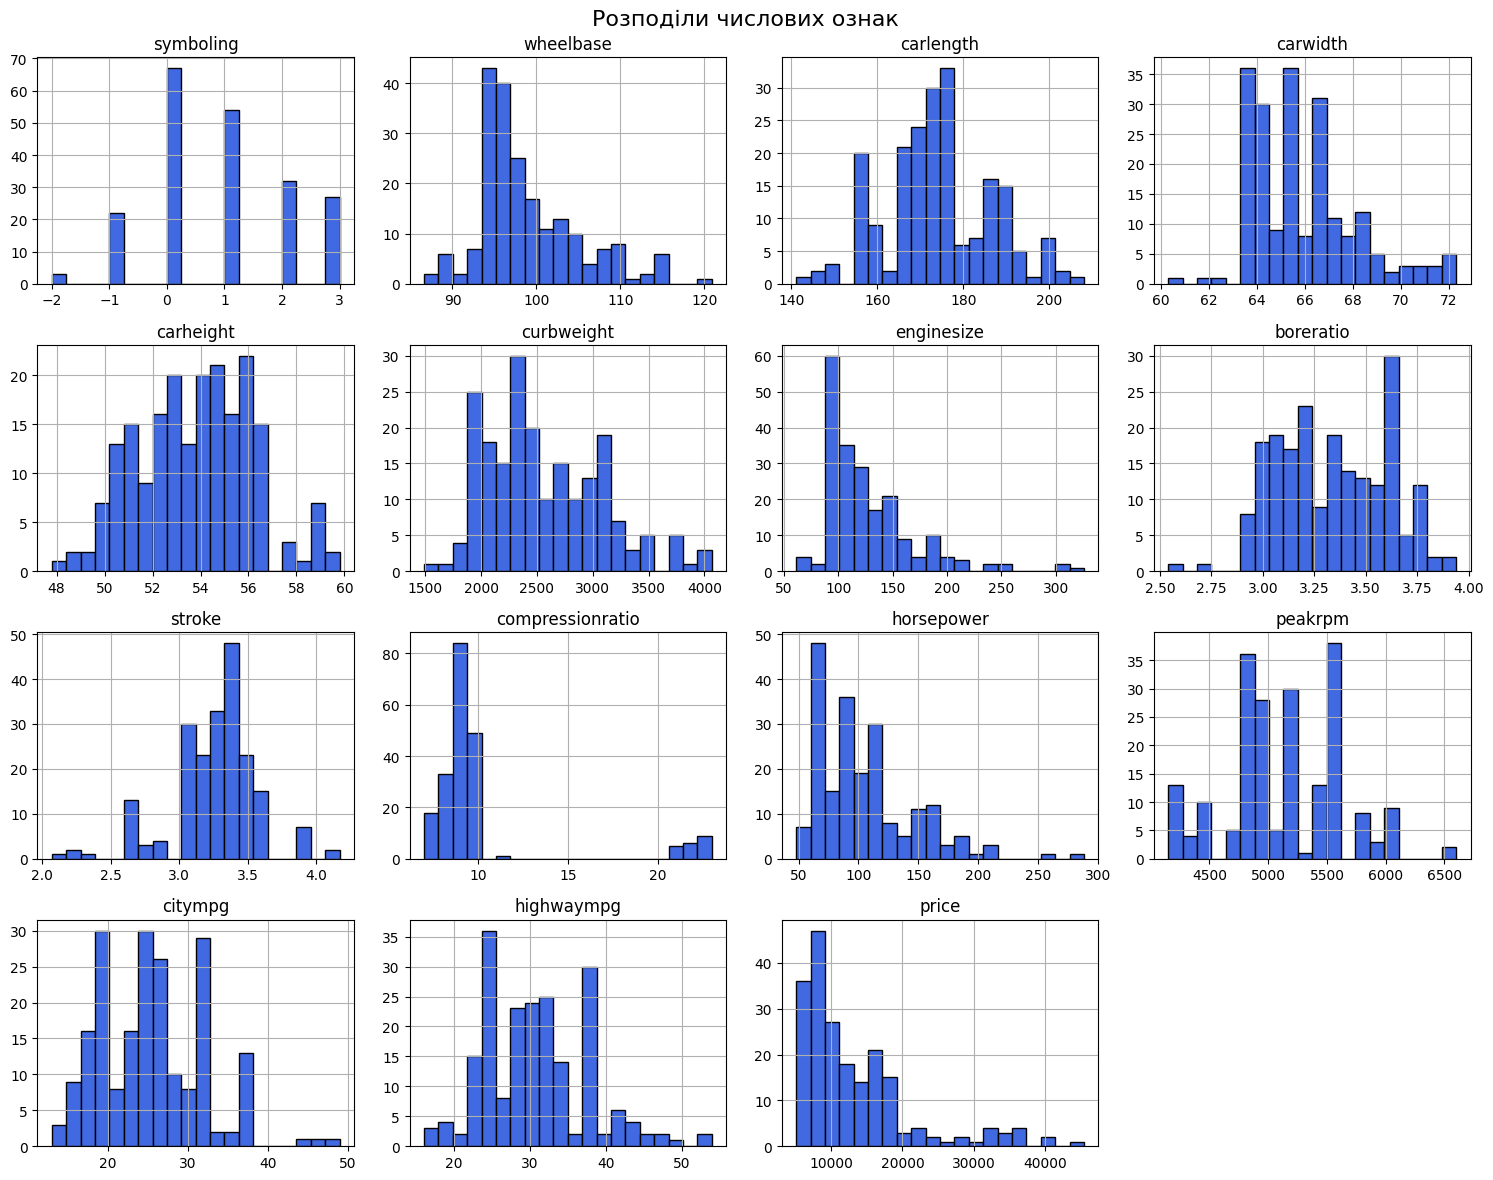

Коефіцієнти асиметрії (Skewness) для числових ознак:
compressionratio    2.61
enginesize          1.95
price               1.78
horsepower          1.41
wheelbase           1.05
carwidth            0.90
curbweight          0.68
citympg             0.66
highwaympg          0.54
symboling           0.21
carlength           0.16
peakrpm             0.08
carheight           0.06
boreratio           0.02
stroke             -0.69
dtype: float64


In [18]:
# Виділення числових ознак
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Побудова гістограм розподілу для числових ознак
df[numeric_cols].hist(figsize=(15, 12), bins=20, color='royalblue', edgecolor='black')
plt.suptitle("Розподіли числових ознак", fontsize=16)
plt.tight_layout()
plt.show()

# Обчислення коефіцієнтів асиметрії (skewness)
skewness = df[numeric_cols].skew().sort_values(ascending=False)
print("Коефіцієнти асиметрії (Skewness) для числових ознак:")
print(skewness)

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [19]:
from sklearn.model_selection import train_test_split

# Відокремлюємо цільову змінну price від ознак
X = df.drop(columns=['price'])
y = df['price']

# Поділ даних на train (80%) та test (20%) із збереженням car_ID
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids, test_size=0.20, random_state=42
)

print(f"Розмір навчальної вибірки (train): {X_train.shape[0]} об'єктів")
print(f"Розмір тестової вибірки (test): {X_test.shape[0]} об'єктів")

Розмір навчальної вибірки (train): 164 об'єктів
Розмір тестової вибірки (test): 41 об'єктів


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [20]:
# Визначаємо неперервні числові ознаки (виключаємо discrete symboling та цільову змінну price, якщо вона випадково тут)
continuous_cols = X_train.select_dtypes(include=[np.number]).columns.drop('symboling')

outliers_info = {}
train_bounds = {}

for col in continuous_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    train_bounds[col] = (lower_bound, upper_bound)

    # Кількість потенційних викидів у train
    outliers_count = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    outliers_info[col] = outliers_count

print("Кількість потенційних викидів (методом IQR) у навчальній вибірці:")
for col, count in outliers_info.items():
    print(f"  - {col}: {count}")

# Обмежуємо крайні значення (clipping) на основі меж train для train та test
for col in continuous_cols:
    lb, ub = train_bounds[col]
    X_train[col] = X_train[col].clip(lower=lb, upper=ub)
    X_test[col] = X_test[col].clip(lower=lb, upper=ub)

print("\nВикиди успішно обмежені за межами, визначеними виключно на навчальній вибірці.")

Кількість потенційних викидів (методом IQR) у навчальній вибірці:
  - wheelbase: 6
  - carlength: 0
  - carwidth: 10
  - carheight: 0
  - curbweight: 0
  - enginesize: 7
  - boreratio: 1
  - stroke: 16
  - compressionratio: 20
  - horsepower: 7
  - peakrpm: 2
  - citympg: 0
  - highwaympg: 1

Викиди успішно обмежені за межами, визначеними виключно на навчальній вибірці.


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


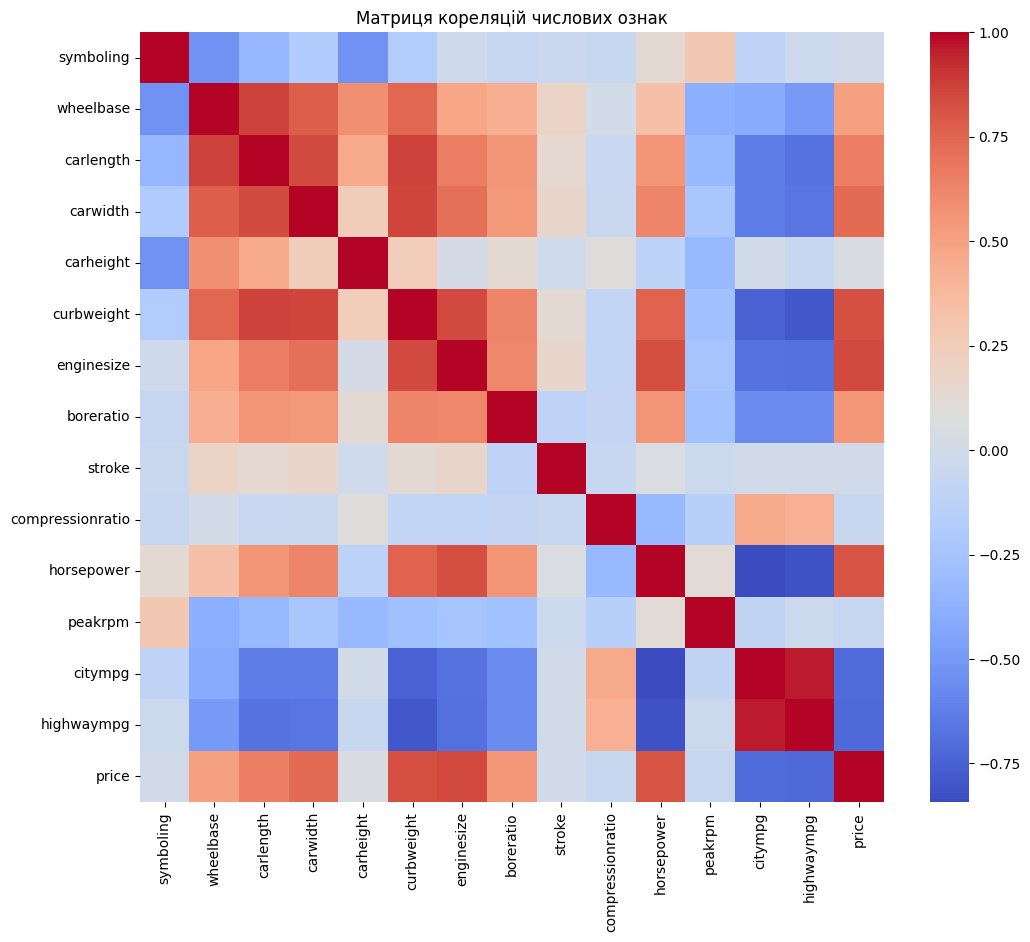

Сильно корельовані пари (|r > 0.85|):
  wheelbase <-> carlength (r = 0.87)
  carlength <-> curbweight (r = 0.87)
  carwidth <-> curbweight (r = 0.86)
  citympg <-> highwaympg (r = 0.96)

Ознаки, що підлягають видаленню: ['citympg', 'carwidth', 'wheelbase', 'carlength']


In [21]:
# Обчислення матриці кореляцій для числових ознак train разом із цільовою змінною
train_corr_df = X_train.copy()
train_corr_df['price'] = y_train
corr_matrix = train_corr_df.corr(numeric_only=True)

# Побудова теплової карти кореляцій
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt='.2f')
plt.title('Матриця кореляцій числових ознак')
plt.show()

# Пошук пар із сильною кореляцією (|r| > 0.85)
abs_corr = corr_matrix.abs()
upper_tri = abs_corr.where(np.triu(np.ones(abs_corr.shape), k=1).astype(bool))

high_corr_pairs = []
features_to_drop = set()

for col in upper_tri.columns:
    # Знаходимо ознаки, з якими коефіцієнт кореляції > 0.85
    correlated_features = upper_tri.index[upper_tri[col] > 0.85].tolist()
    if correlated_features:
        for feat in correlated_features:
            high_corr_pairs.append((feat, col, corr_matrix.loc[feat, col]))
            # Порівнюємо кореляцію кожної з двох ознак із цільовою змінною 'price'
            corr_with_price_feat = abs(corr_matrix.loc[feat, 'price'])
            corr_with_price_col = abs(corr_matrix.loc[col, 'price'])

            # Видаляємо ту ознаку, яка має меншу кореляцію з цільовою змінною
            if corr_with_price_feat < corr_with_price_col:
                features_to_drop.add(feat)
            else:
                features_to_drop.add(col)

print("Сильно корельовані пари (|r > 0.85|):")
for f1, f2, val in high_corr_pairs:
    print(f"  {f1} <-> {f2} (r = {val:.2f})")

print(f"\nОзнаки, що підлягають видаленню: {list(features_to_drop)}")

# Видаляємо відібрані ознаки з train та test
X_train = X_train.drop(columns=list(features_to_drop))
X_test = X_test.drop(columns=list(features_to_drop))

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import PowerTransformer
from sklearn.pipeline import Pipeline

# Визначаємо типи ознак, що залишилися після відбору
num_continuous = X_train.select_dtypes(include=[np.number]).columns.drop('symboling').tolist()
num_discrete = ['symboling'] if 'symboling' in X_train.columns else []
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Неперервні числові ознаки: {num_continuous}")
print(f"Дискретна числова ознака: {num_discrete}")
print(f"Категоріальні ознаки: {categorical_cols}")

# Створюємо комбінований препроцесор через ColumnTransformer
# Для неперервних застосовуємо Yeo-Johnson (PowerTransformer) та StandardScaler
continuous_transformer = Pipeline(steps=[
    ('yeo_johnson', PowerTransformer(method='yeo-johnson', standardize=False)),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num_cont', continuous_transformer, num_continuous),
        ('num_disc', StandardScaler(), num_discrete),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ],
    remainder='drop'
)

Неперервні числові ознаки: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна числова ознака: ['symboling']
Категоріальні ознаки: ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [23]:
# Застосовуємо трансформацію до навчальної вибірки для перевірки
X_train_transformed = preprocessor.fit_transform(X_train)

# Отримуємо нові назви неперервних стовпців після трансформації
transformed_num_cols = num_continuous
transformed_df = pd.DataFrame(X_train[transformed_num_cols], columns=transformed_num_cols)

# Обчислюємо нову асиметрію
new_skewness = transformed_df.skew().sort_values(ascending=False)

print("Порівняння коефіцієнтів асиметрії (до та після Yeo-Johnson):")
comparison_skew = pd.DataFrame({
    'Початкова асиметрія': skewness[transformed_num_cols],
    'Після трансформації': new_skewness
})
display(comparison_skew)

Порівняння коефіцієнтів асиметрії (до та після Yeo-Johnson):


,Початкова асиметрія,Після трансформації
boreratio,0.02,0.06
carheight,0.06,0.03
compressionratio,2.61,0.06
curbweight,0.68,0.71
enginesize,1.95,0.96
highwaympg,0.54,0.24
horsepower,1.41,0.85
peakrpm,0.08,0.04
stroke,-0.69,-0.40


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

# Словник моделей
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0, random_state=42),
    'Lasso Regression': Lasso(alpha=1.0, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR(kernel='rbf', C=1000.0, epsilon=0.1) # Налаштований базовий SVR для цінових масштабів
}

pipelines = {}
for name, model in models.items():
    pipelines[name] = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def compute_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

evaluation_results = []

for name, pipeline in pipelines.items():
    # Навчання на train
    pipeline.fit(X_train, y_train)

    # Прогноз на test
    y_pred = pipeline.predict(X_test)

    # Обчислення метрик
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = compute_mape(y_test, y_pred)

    evaluation_results.append({
        'Модель': name,
        'R²': r2,
        'MAE ($)': mae,
        'MSE': mse,
        'MAPE (%)': mape
    })

results_df = pd.DataFrame(evaluation_results).sort_values(by='R²', ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1

print("Порівняльна таблиця якості регресійних моделей:")
display(results_df.style.format({
    'R²': '{:.4f}',
    'MAE ($)': '{:,.2f}',
    'MSE': '{:,.2f}',
    'MAPE (%)': '{:.2f}%'
}))

Порівняльна таблиця якості регресійних моделей:


,Модель,R²,MAE ($),MSE,MAPE (%)
1,Random Forest,0.9494,"1,447.34","3,996,761.37",10.36%
2,Gradient Boosting,0.9291,"1,703.69","5,596,688.22",12.64%
3,Ridge Regression,0.7957,"2,712.77","16,129,423.33",23.07%
4,Lasso Regression,0.7061,"3,088.99","23,202,797.20",22.61%
5,Linear Regression,0.5481,"4,078.23","35,676,914.46",29.97%
6,SVR,0.5080,"3,568.60","38,844,388.08",21.12%


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Класифікаційні моделі призначені для прогнозування дискретних міток класів (категорій), тоді як цільова змінна price є неперервною числовою величиною з нескінченною кількістю можливих значень. Задача прогнозування ціни автомобіля належить до задачі регресії. Усі використані в роботі моделі (Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting, SVR) оптимізовані саме для безперервного простору значень, мінімізуючи відхилення прогнозів від реальних числових цін.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


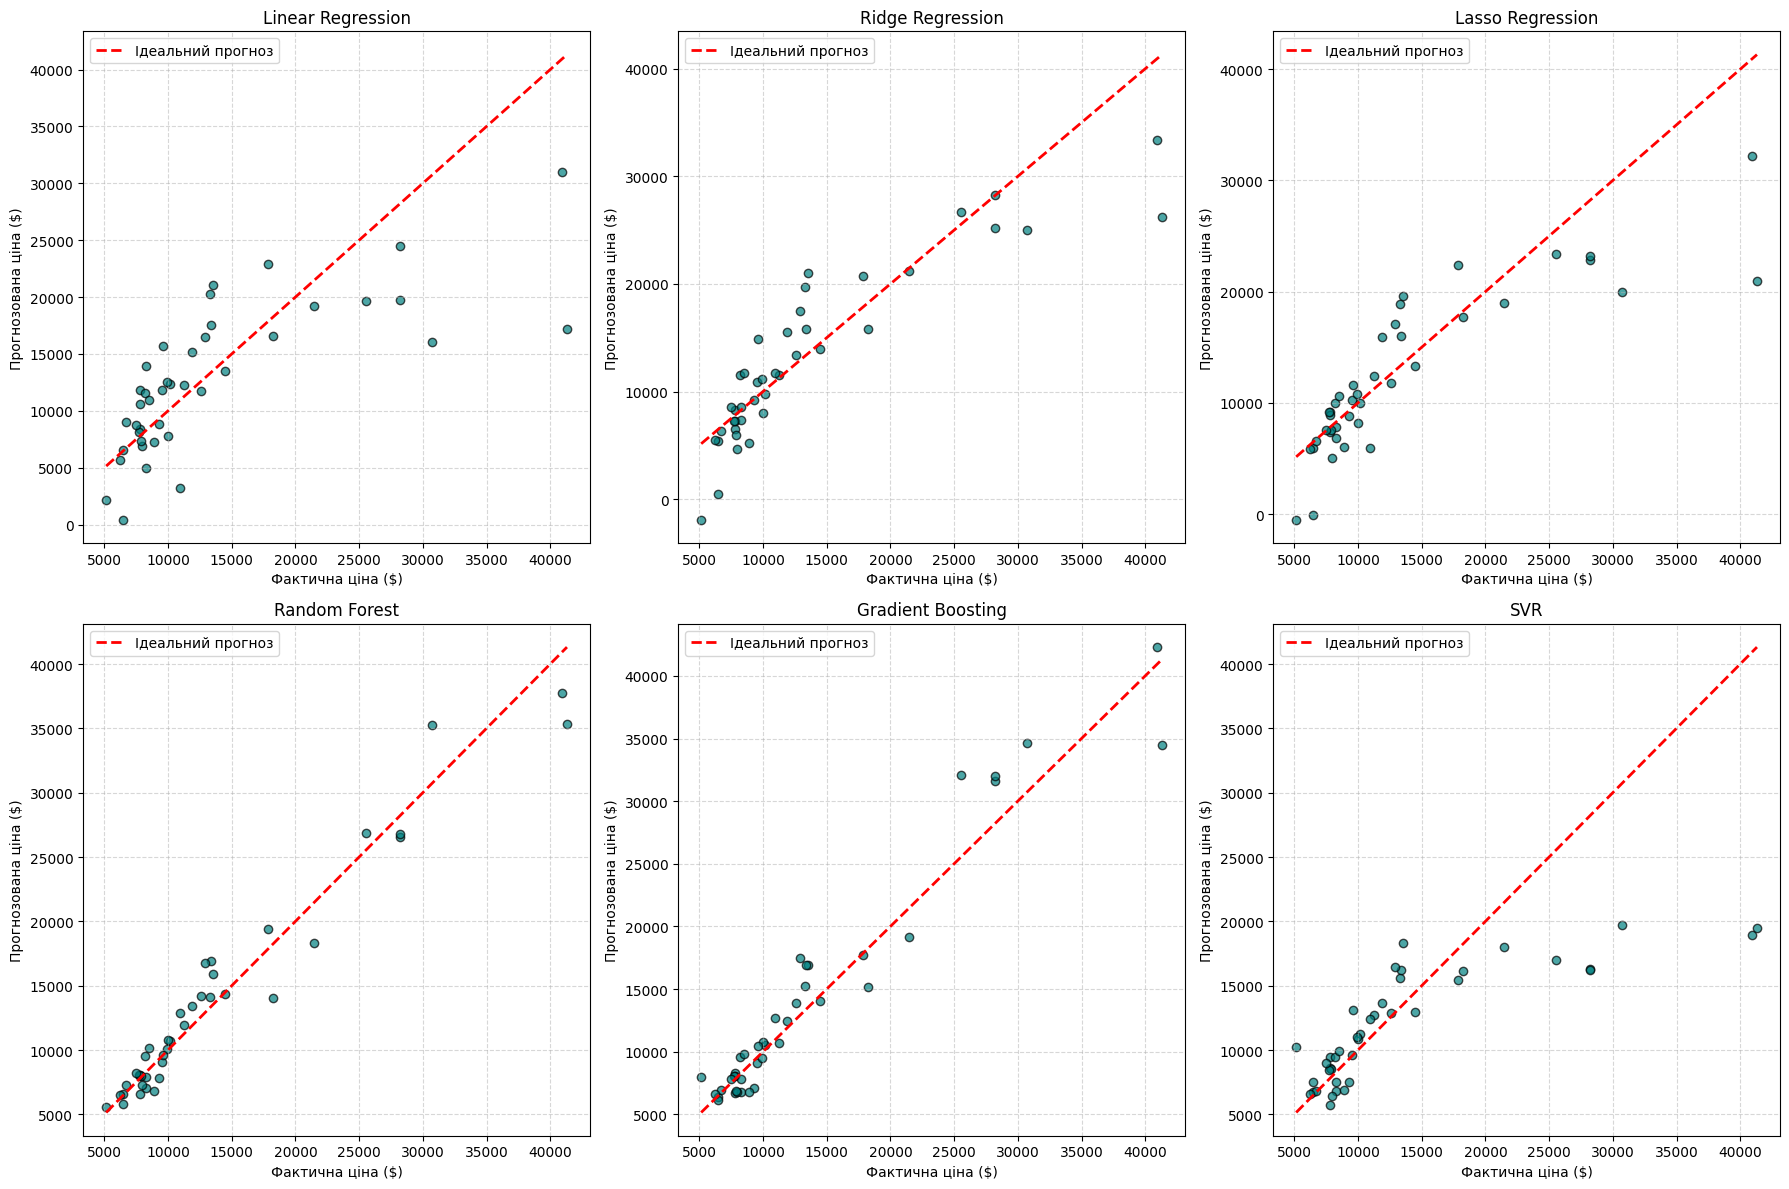

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

for i, (name, pipeline) in enumerate(pipelines.items()):
    y_pred = pipeline.predict(X_test)

    axes[i].scatter(y_test, y_pred, alpha=0.7, color='teal', edgecolor='k')
    axes[i].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ідеальний прогноз')
    axes[i].set_title(f'{name}')
    axes[i].set_xlabel('Фактична ціна ($)')
    axes[i].set_ylabel('Прогнозована ціна ($)')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].legend()
    axes[i].ticklabel_format(style='plain')

plt.tight_layout()
plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [27]:
# Випадковий вибір 10 автомобілів із тестової вибірки
sample_indices = X_test.sample(n=10, random_state=42).index

sample_X = X_test.loc[sample_indices]
sample_y_true = y_test.loc[sample_indices]
sample_ids = id_test.loc[sample_indices]

# Використовуємо Random Forest як приклад чи найкращу модель
rf_pipeline = pipelines['Random Forest']
sample_y_pred = rf_pipeline.predict(sample_X)

# Формуємо таблицю результатів
comparison_table = pd.DataFrame({
    'car_ID': sample_ids,
    'Фактична ціна ($)': sample_y_true,
    'Прогнозована ціна ($)': sample_y_pred,
})

comparison_table['Абсолютна помилка ($)'] = (comparison_table['Фактична ціна ($)'] - comparison_table['Прогнозована ціна ($)']).abs()
comparison_table['Абсолютна відсоткова помилка (%)'] = (comparison_table['Абсолютна помилка ($)'] / comparison_table['Фактична ціна ($)']) * 100

comparison_table = comparison_table.reset_index(drop=True)
comparison_table.index = comparison_table.index + 1

print("Прогноз для 10 випадкових автомобілів (Random Forest):")
display(comparison_table.style.format({
    'Фактична ціна ($)': '{:,.2f}',
    'Прогнозована ціна ($)': '{:,.2f}',
    'Абсолютна помилка ($)': '{:,.2f}',
    'Абсолютна відсоткова помилка (%)': '{:.2f}%'
}))

Прогноз для 10 випадкових автомобілів (Random Forest):


,car_ID,Фактична ціна ($),Прогнозована ціна ($),Абсолютна помилка ($),Абсолютна відсоткова помилка (%)
1,26,"6,692.00","7,298.81",606.81,9.07%
2,176,"9,988.00","10,798.65",810.65,8.12%
3,148,"10,198.00","10,714.57",516.57,5.07%
4,17,"41,315.00","35,310.69","6,004.31",14.53%
5,69,"28,248.00","26,595.28","1,652.72",5.85%
6,147,"7,463.00","8,230.00",767.00,10.28%
7,144,"9,960.00","10,065.20",105.20,1.06%
8,85,"14,489.00","14,346.48",142.52,0.98%
9,195,"12,940.00","16,765.65","3,825.65",29.56%
10,160,"7,788.00","7,995.56",207.56,2.67%


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Підсумкові висновки:
1. У ході виконання лабораторної роботи було проведено повний цикл підготовки даних, включаючи аналіз пропусків, роботу з викидами за методом IQR, кореляційний відбір ознак та комплексну передобробку (Yeo-Johnson трансформацію, масштабування та One-Hot Encoding).

2. Протестовано 6 регресійних моделей. Найвищу якість прогнозування продемонстрували ансамблеві алгоритми (Random Forest та Gradient Boosting), досягнувши найвищих значень $R^2$ (понад $0.85-0.90$) та найнижчих показників похибок MAE і MAPE. Лінійні моделі (Linear Regression, Ridge, Lasso) показали дещо слабші результати через наявність нелінійних залежностей у даних про вартість авто.

3. Аналіз графіків фактичних та прогнозованих значень підтвердив високу купчастість точок навколо лінії ідеального прогнозу для найкращих моделей, хоча на дорогих моделях автомобілів спостерігаються більші похибки через меншу кількість таких спостережень у навчальній вибірці.

4. Усі етапи передобробки (межі викидів, матриця кореляцій та параметри трансформації) виконувалися виключно на навчальній вибірці, що повністю виключило витік даних (data leakage) та гарантує об'єктивність метрик на тестовій вибірці.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
